# Synthetic global S-curves ($L$, $C_0$, $k$, $t_0$)

First step of a three-notebook pipeline:

1. **This notebook** -- fit $L$, $C_0$, $k$, $t_0$ to the real GCAM donor curve (summed across all 32 regions) and generate tunable synthetic global S-curves (Mt CO2/yr).
2. `create-synthetic-global-rock-schedules.ipynb` -- takes these curves as the *target*, rescales the real 32-region split to match them timestep-by-timestep, and writes new `dfrock`/`dsag` schedules to S3.
3. `cdr-gcam-globalscaling-constApp-multiSchedule-COILED.ipynb` -- runs those schedules through the SCEPTER-based global CDR scaling to get CDR outcomes.

Uses the same 4-parameter logistic explored in `tests/scratch-nemet-scalecurves.ipynb`, now fit directly to the global Mt CO2/yr curve (rather than the local rock-application CSV used there) so units line up with what the downstream notebooks expect:

$$C(t) = \frac{C_0 L}{C_0 + (L-C_0) e^{-k(t-t_0)}}$$

Where $C_0$ is the prescribed capacity at reference year $t_0$, $L$ is the asymptotic max scale capacity, and $k$ is the growth-rate coefficient.

# S-curve matrix
This script assumes that we want $N \times k \times L$ S-curves, where $N$ is some set of $C_0$, $t_0$ combinations, and $k$ is some set of $k$ values, and $L$ is some set of asymptote $L$ values. 

We define $M$ and $N$ up top, plot the resulting curves, and save them. At the bottom we justify the decisions with comparison to the GCAM curve. 

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import s3fs
import xarray as xr
from scipy.optimize import curve_fit

## Config

In [ ]:
# --- [ donor schedule: real GCAM data we fit L, C0, k, t0 against ] ---
BASE_SCHEDULE = 'exe_central1p5'
RUN_FORMAT    = 'one-cell-per-region'
DEG_RES       = 1

# --- [ representative SCEPTER run -- used only to auto-detect a valid apprate to read
#       gcam_gross_cdr_mtCO2 from. That column is apprate-invariant (confirmed in
#       create-synthetic-global-rock-schedules.ipynb), so any one apprate works fine here. ] ---
EXP_GROUP  = 'gcam_opr_full_cec1'
EXP_SET    = 'exe_central1p5'
SAVE_GROUP = 'gcam'
idx        = '001'

RCO2_GCAM = 0.3  # tCO2 / t basalt, same constant used elsewhere in this repo

S3_BASE = f's3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/{RUN_FORMAT}'
rock_fn = f'annual_rockflx_densest-ag-region_{DEG_RES}deg.pkl'

# --- [ where the synthetic curves get saved for create-synthetic-global-rock-schedules.ipynb --
#       one CSV per case, plus a small manifest CSV of the params used ] ---
SAVE_TO_S3 = True
# if False, the save cell refuses to write (and lists the conflicts) when any destination
# file already exists on S3, instead of silently overwriting it
OVERWRITE_EXISTING = False
S3_SAVE_DIR = ('s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/'
               'one-cell-per-region/synthetic-rateConstrained')
manifest_fn = f'{S3_SAVE_DIR}/manifest.csv'


def curve_path(schedule_name):
    return f'{S3_SAVE_DIR}/{schedule_name}.csv'

## Read in and fit the GCAM donor curve (sum of 32 regions)
Reads one `dfrock` pkl (any apprate -- `gcam_gross_cdr_mtCO2` doesn't vary with apprate) and sums `gcam_gross_cdr_mtCO2` across all regions to get the real global curve we'll fit the logistic to.

reading gcam_gross_cdr_mtCO2 from apprate=0.1-tHaYr-appRate-FIXED (apprate-invariant column, any one works)
32 regions, years 2020-2100
exe_central1p5 global cumulative total: 282,193 Mt CO2
GCAM best fit (exe_central1p5, anchored at t0=2026):
  C0 = 213.4 Mt CO2/yr
  L  = 4,630.9 Mt CO2/yr
  k  = 0.240 yr^-1  (doubling time ~2.9 yr)


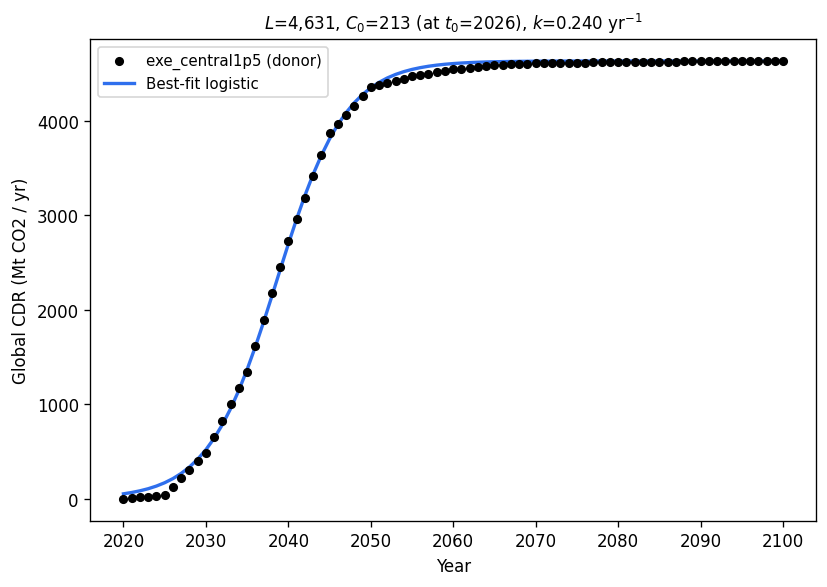

In [3]:
# [ READ IN DATA ]
datpath = f"s3://carbonplan-carbon-removal/ew-workflows-data/scepter/postprocessed/{SAVE_GROUP}/{EXP_GROUP}/{EXP_SET}_{idx}"
ds_rep_meta = xr.open_zarr(os.path.join(datpath, 'ds_cdr.zarr'))
apprate_ref = float(np.unique(ds_rep_meta.apprate_base.values)[0])
apprate_name = f'{apprate_ref}-tHaYr-appRate-FIXED'
print(f'reading gcam_gross_cdr_mtCO2 from apprate={apprate_name} (apprate-invariant column, any one works)')

gcam_dir = f'{S3_BASE}/{BASE_SCHEDULE}/{apprate_name}'
df_base = pd.read_pickle(os.path.join(gcam_dir, rock_fn))

years = np.sort(df_base['time'].unique()).astype(float)
n_regions = df_base['region_nospaces'].nunique()
print(f'{n_regions} regions, years {years.min():.0f}-{years.max():.0f}')

baseline_global_mtco2 = (
    df_base.groupby('time')['gcam_gross_cdr_mtCO2'].sum().reindex(years).values
)
baseline_total_mtco2 = np.trapezoid(baseline_global_mtco2, years)
print(f'{BASE_SCHEDULE} global cumulative total: {baseline_total_mtco2:,.0f} Mt CO2')

# [ FIT LOGISTIC CURVE ]
def logistic4(t, C0, L, k, t0):
    """C(t) = C0*L / (C0 + (L-C0)*e^{-k(t-t0)})."""
    return C0 * L / (C0 + (L - C0) * np.exp(-k * (t - t0)))


T0_REF = 2026  # reference year to anchor C0 to (degenerate with any other t0 -- see markdown)

fit_fn = lambda t, C0, L, k: logistic4(t, C0, L, k, T0_REF)
c0_guess = max(float(np.interp(T0_REF, years, baseline_global_mtco2)), 1e-6)
popt, _ = curve_fit(
    fit_fn, years, baseline_global_mtco2, p0=[c0_guess, baseline_global_mtco2.max() * 3, 0.2],
    bounds=([1e-9, baseline_global_mtco2.max(), 1e-4], [np.inf, np.inf, 2.0]),
    maxfev=20000,
)
C0_fit, L_fit, k_fit = popt

print(f'GCAM best fit ({BASE_SCHEDULE}, anchored at t0={T0_REF}):')
print(f'  C0 = {C0_fit:,.1f} Mt CO2/yr')
print(f'  L  = {L_fit:,.1f} Mt CO2/yr')
print(f'  k  = {k_fit:.3f} yr^-1  (doubling time ~{np.log(2) / k_fit:.1f} yr)')

# ——————————————————————————————————————————————————————————————————
# [ PLOT ]
fig, ax = plt.subplots(figsize=(7, 5), dpi=120)
ax.scatter(years, baseline_global_mtco2, color='k', s=20, zorder=3, label=f'{BASE_SCHEDULE} (donor)')
ax.plot(years, logistic4(years, C0_fit, L_fit, k_fit, T0_REF), color='#2f6fed', lw=2, label='Best-fit logistic')
ax.set_xlabel('Year')
ax.set_ylabel('Global CDR (Mt CO2 / yr)')
ax.set_title(f'$L$={L_fit:,.0f}, $C_0$={C0_fit:,.0f} (at $t_0$={T0_REF}), $k$={k_fit:.3f} yr$^{{-1}}$', fontsize=10)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## Define synthetic cases
Set the C0-t0 pairs, k values, and L values. Then generate a synthesized dict that includes the full matrix of input parameters.

**Near-term ramp.** A case whose $C_0$ is *derived* from a prescribed scale-up (rather than measured at $t_0$) also carries a `ramp` entry, and the curve follows that exponential up to $t_0$ before switching to the logistic at the case's own $k$.

In [4]:
# set empirical C0 constraints
YR_BASE_CDRFYI = 2026
YR_RAMP_END    = 2036
C0_SALES_2026  = 807.885e3 * 1e-6  # [Mt] cdr.fyi ERW sales (6/2026)
C0_DELIV_2026  = 30.7e3 * 1e-6     # [Mt] cdr.fyi ERW deliveries (6/2026)
# [k inputs]
K_GCAM_10YR    = 0.52            # [yr-1] GCAM near-term growth rate (first 10 years, pinned to first year of data)
K_GCAM_FULL    = k_fit           # [yr-1] GCAM full data growth rate
K_NEMET_MEDIAN = 0.13            # [yr-1] median value of Nemet et al. 2023
# [L inputs]
L_GCAM         = L_fit    # [Mt] peak value
L_LOWER        = 2e3      # [Mt] peak value
L_LOWEST       = 0.5e3    # [Mt] peak value

# [ C0 and t0 values ]
# defines the near-term ambition / starting condition
#
# "ramp" (optional): the prescribed near-term scale-up that this case's C0 was *derived* from,
# as opposed to measured at t0. Where it's set, the curve follows that exponential up to t0 and
# only switches to the logistic (at the case's own k) from t0 on -- so every k shares an
# identical first decade. See the markdown above for why the alternative (letting each logistic
# back-extrapolate its own long-term k) gets the near term backwards.
C0t0_dict = {
    "nearterm-gcam-first10yrs": {
        "C0": C0_SALES_2026 * np.exp(K_GCAM_10YR * (YR_RAMP_END - YR_BASE_CDRFYI)),
        "t0": YR_RAMP_END,
        "ramp": {"C_ref": C0_SALES_2026, "t_ref": YR_BASE_CDRFYI, "k": K_GCAM_10YR},
    },
    "cdrfyi-sales": {
        "C0": C0_SALES_2026,
        "t0": YR_BASE_CDRFYI,
    },
    "cdrfyi-deliveries": {
        "C0": C0_DELIV_2026,
        "t0": YR_BASE_CDRFYI,
    }
}

# [ k values ]
# defines the fixed growth rate / doubling time
k_dict = {
    "k_gcam": K_GCAM_FULL,
    "k_nemetMedian": K_NEMET_MEDIAN,
}

# [ L values ]
# defines the asymptote
L_dict = {
    "L_gcam":  L_GCAM, # don't add the GCAM best fit since we already have the GCAM data
    f"L{L_LOWER/1e3}Gt":   L_LOWER,
    f"L{L_LOWEST/1e3}Gt":  L_LOWEST
}


def build_curve(years, C0, L, k, t0, ramp=None):
    """logistic4 from t0 onward; before t0, either the prescribed `ramp` exponential (identical
    for every k, since it doesn't depend on k at all) or -- with no ramp -- the logistic's own
    backward extrapolation, which is what a case with C0 measured at t0 wants.

    The two pieces meet at t0 by construction: C_ref * exp(k_ramp * (t0 - t_ref)) is exactly how
    a ramped C0 is defined above. The kink in slope there is intentional -- it's the handoff from
    the near-term ramp to the long-term growth rate."""
    curve = logistic4(years, C0, L, k, t0)
    if ramp is None:
        return curve
    ramp_curve = ramp["C_ref"] * np.exp(ramp["k"] * (years - ramp["t_ref"]))
    return np.where(years < t0, ramp_curve, curve)


# [ build the full C0t0 x k x L combination matrix ]
s_curve_param_dict = {
    f"{c0t0_key}_{k_key}_{L_key}": {
        "C0": c0t0_vals["C0"],
        "t0": c0t0_vals["t0"],
        "k": k_val,
        "L": L_val,
        "ramp": c0t0_vals.get("ramp"),
    }
    for c0t0_key, c0t0_vals in C0t0_dict.items()
    for k_key, k_val in k_dict.items()
    for L_key, L_val in L_dict.items()
}

print(f'{len(s_curve_param_dict)} synthetic S-curves:')
for name, p in s_curve_param_dict.items():
    ramp_note = ('' if p['ramp'] is None else
                 f"  ramp: {p['ramp']['C_ref']:,.2f} Mt at {p['ramp']['t_ref']:.0f}, "
                 f"k={p['ramp']['k']:.2f} until t0")
    print(f"  {name:45s} C0={p['C0']:>10,.2f}  L={p['L']:>10,.2f}  k={p['k']:.3f}  t0={p['t0']:.0f}{ramp_note}")

# ——————————————————————————————————————————————
# build the synthetic curves
synthetic_curves = {
    name: build_curve(years, p['C0'], p['L'], p['k'], p['t0'], p['ramp'])
    for name, p in s_curve_param_dict.items()
}

# the ramp and the logistic are *defined* to meet at t0 -- verify that, don't assume it, and
# confirm the shared first decade actually came out shared across k
for c0t0_key, c0t0_vals in C0t0_dict.items():
    ramp = c0t0_vals.get('ramp')
    if ramp is None:
        continue
    ramp_at_t0 = ramp['C_ref'] * np.exp(ramp['k'] * (c0t0_vals['t0'] - ramp['t_ref']))
    np.testing.assert_allclose(
        ramp_at_t0, c0t0_vals['C0'], rtol=1e-12,
        err_msg=f'{c0t0_key}: ramp end point != C0, so the curve would jump at t0',
    )
    pre_t0 = years < c0t0_vals['t0']
    for L_key in L_dict:
        ref = synthetic_curves[f'{c0t0_key}_{next(iter(k_dict))}_{L_key}'][pre_t0]
        for k_key in k_dict:
            np.testing.assert_allclose(
                synthetic_curves[f'{c0t0_key}_{k_key}_{L_key}'][pre_t0], ref, rtol=1e-12,
                err_msg=f'{c0t0_key}_{k_key}_{L_key}: pre-t0 window differs between k cases',
            )
    print(f'{c0t0_key}: ramp/logistic handoff continuous at t0, and the pre-{c0t0_vals["t0"]:.0f} '
          f'window is identical across all {len(k_dict)} k cases')

18 synthetic S-curves:
  nearterm-gcam-first10yrs_k_gcam_L_gcam        C0=    146.45  L=  4,630.86  k=0.240  t0=2036  ramp: 0.81 Mt at 2026, k=0.52 until t0
  nearterm-gcam-first10yrs_k_gcam_L2.0Gt        C0=    146.45  L=  2,000.00  k=0.240  t0=2036  ramp: 0.81 Mt at 2026, k=0.52 until t0
  nearterm-gcam-first10yrs_k_gcam_L0.5Gt        C0=    146.45  L=    500.00  k=0.240  t0=2036  ramp: 0.81 Mt at 2026, k=0.52 until t0
  nearterm-gcam-first10yrs_k_nemetMedian_L_gcam C0=    146.45  L=  4,630.86  k=0.130  t0=2036  ramp: 0.81 Mt at 2026, k=0.52 until t0
  nearterm-gcam-first10yrs_k_nemetMedian_L2.0Gt C0=    146.45  L=  2,000.00  k=0.130  t0=2036  ramp: 0.81 Mt at 2026, k=0.52 until t0
  nearterm-gcam-first10yrs_k_nemetMedian_L0.5Gt C0=    146.45  L=    500.00  k=0.130  t0=2036  ramp: 0.81 Mt at 2026, k=0.52 until t0
  cdrfyi-sales_k_gcam_L_gcam                    C0=      0.81  L=  4,630.86  k=0.240  t0=2026
  cdrfyi-sales_k_gcam_L2.0Gt                    C0=      0.81  L=  2,000.00  k=

### Plot synthetic curves against GCAM donor

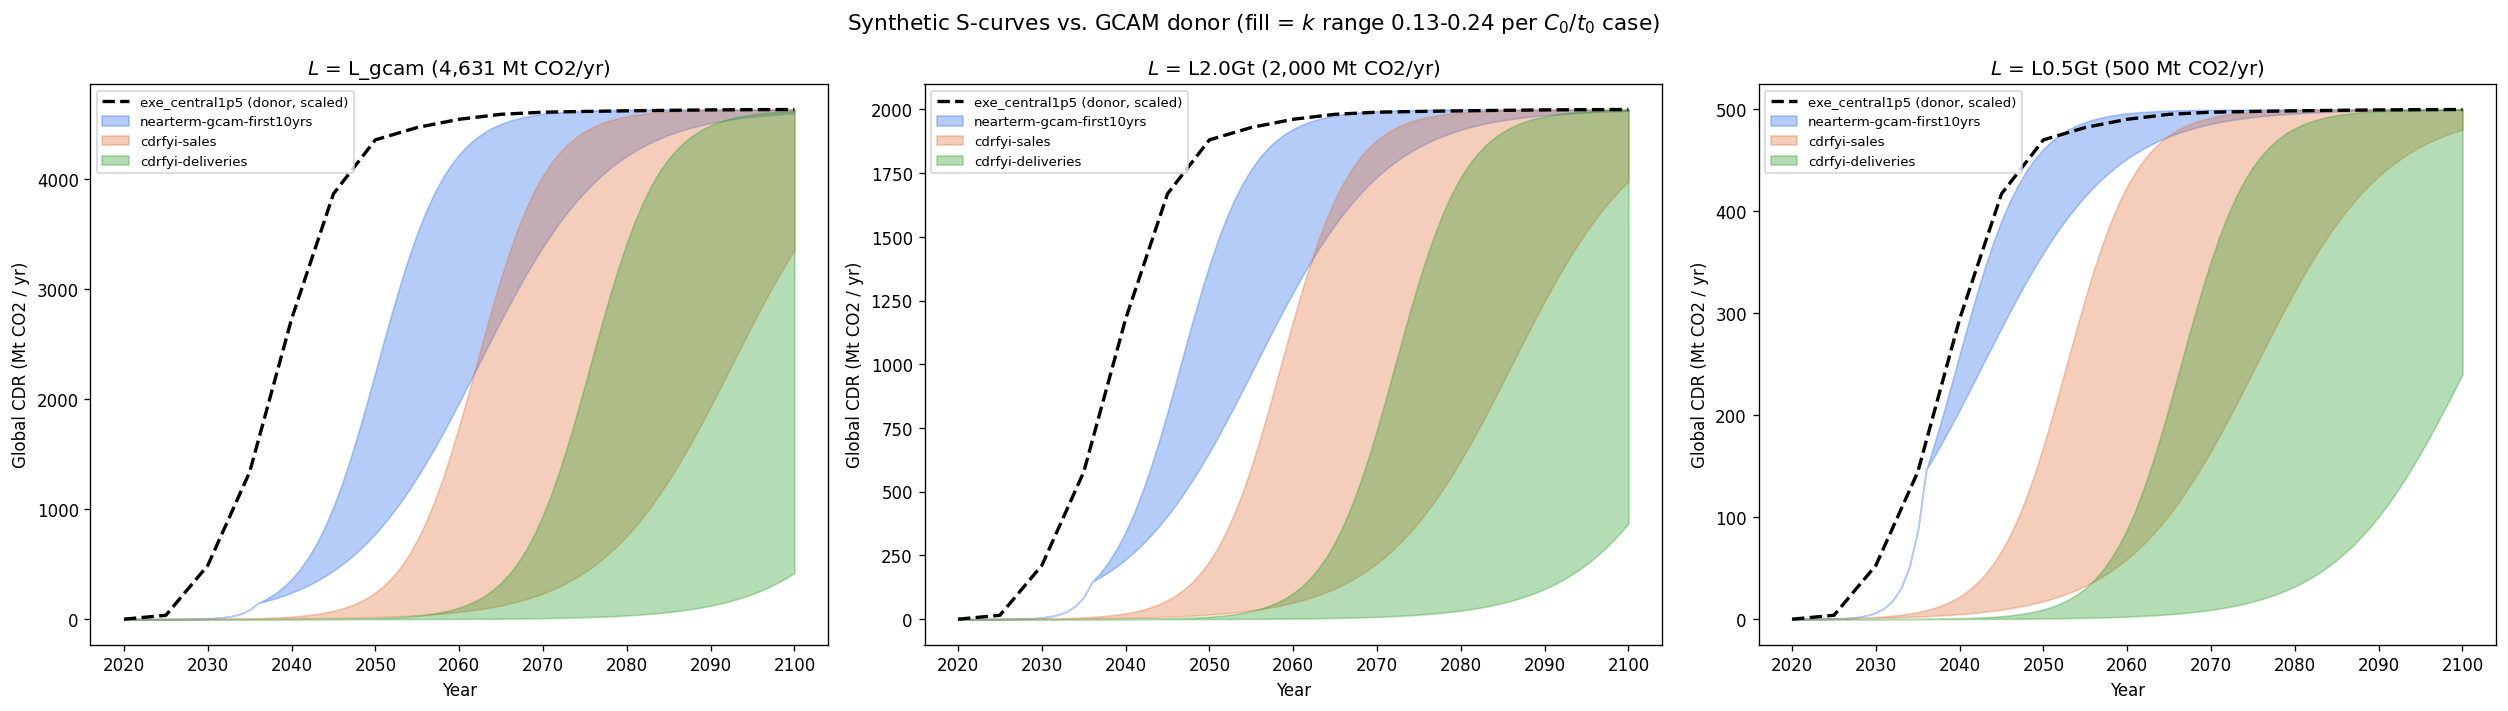

In [5]:
CASE_COLORS = dict(zip(C0t0_dict.keys(), ["#2f6fed", "#e0733a", "#2ca02c", "#9467bd", "#8c564b"]))
k_lo, k_hi = min(k_dict.values()), max(k_dict.values())

fig, axes = plt.subplots(1, len(L_dict), figsize=(7 * len(L_dict), 6), dpi=120, sharey=False)
if len(L_dict) == 1:
    axes = [axes]

for ax, (L_key, L_val) in zip(axes, L_dict.items()):
    # GCAM donor curve, scaled to this panel's L so the asymptotes are comparable
    donor_scaled = baseline_global_mtco2 * (L_val / L_GCAM)
    ax.plot(years, donor_scaled, 'k--', lw=2, label=f'{BASE_SCHEDULE} (donor, scaled)')

    for c0t0_key, c0t0_vals in C0t0_dict.items():
        # build_curve, not logistic4 -- so this QC plot shows the same curves that actually get
        # saved. For a ramped case the k fill collapses to a single line before t0: that pinch
        # *is* the shared first decade, and its absence would mean the ramp didn't take.
        curve_lo = build_curve(years, c0t0_vals['C0'], L_val, k_lo, c0t0_vals['t0'], c0t0_vals.get('ramp'))
        curve_hi = build_curve(years, c0t0_vals['C0'], L_val, k_hi, c0t0_vals['t0'], c0t0_vals.get('ramp'))
        ax.fill_between(years, np.minimum(curve_lo, curve_hi), np.maximum(curve_lo, curve_hi),
                         color=CASE_COLORS[c0t0_key], alpha=0.35, label=c0t0_key)

    ax.set_xlabel('Year')
    ax.set_ylabel('Global CDR (Mt CO2 / yr)')
    ax.set_title(f'$L$ = {L_key} ({L_val:,.0f} Mt CO2/yr)')
    ax.legend(fontsize=8)

fig.suptitle(f'Synthetic S-curves vs. GCAM donor (fill = $k$ range {k_lo:.2f}-{k_hi:.2f} per $C_0$/$t_0$ case)', fontsize=13)
fig.tight_layout()
plt.show()

## Save
Writes one CSV per case (`{schedule_name}.csv`, columns `year`, `value_mtco2_per_yr`) plus a small `manifest.csv` (the `(C0, L, k, t0)` used per case), to:

`s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/one-cell-per-region/synthetic-rateConstrained/`

One file per curve means `create-synthetic-global-rock-schedules.ipynb` (or anything else downstream) can selectively read in just the cases it needs instead of always loading every curve, e.g.:

```python
synthetic_curves = {
    name: pd.read_csv(f'{S3_SAVE_DIR}/{name}.csv', index_col='year')['value_mtco2_per_yr'].reindex(years).values
    for name in ['gcam_bestfit', 'faster_ramp']  # only pull in the cases you actually want
}
```

In [ ]:
fs = s3fs.S3FileSystem()

# flatten the nested ramp dict into ramp_* columns (NaN for cases with no near-term ramp) so the
# manifest stays a flat CSV -- downstream readers select C0/L/k/t0 by name and are unaffected
manifest = pd.DataFrame.from_dict(
    {
        name: {
            **{key: val for key, val in p.items() if key != 'ramp'},
            **{f'ramp_{rkey}': rval for rkey, rval in (p['ramp'] or {}).items()},
        }
        for name, p in s_curve_param_dict.items()
    },
    orient='index',
)
manifest.index.name = 'schedule_name'
manifest['C0_units'] = 'Mt CO2/yr'
manifest['L_units'] = 'Mt CO2/yr'
manifest['k_units'] = 'yr^-1'
manifest['ramp_C_ref_units'] = 'Mt CO2/yr'
manifest['ramp_k_units'] = 'yr^-1'
manifest['donor_schedule'] = BASE_SCHEDULE
manifest['file'] = [f'{name}.csv' for name in manifest.index]

curve_paths = {name: curve_path(name) for name in synthetic_curves}

if SAVE_TO_S3:
    if not OVERWRITE_EXISTING:
        existing = [fn for fn in list(curve_paths.values()) + [manifest_fn] if fs.exists(fn.replace('s3://', ''))]
        if existing:
            raise FileExistsError(
                'refusing to overwrite existing S3 output (set OVERWRITE_EXISTING = True to '
                'proceed anyway):\n  ' + '\n  '.join(existing)
            )

    for name, curve in synthetic_curves.items():
        pd.Series(curve, index=years, name='value_mtco2_per_yr').rename_axis('year').to_csv(curve_paths[name])
    manifest.to_csv(manifest_fn)

    print(f'saved {len(synthetic_curves)} curve(s) to {S3_SAVE_DIR}/')
    print(f'saved manifest to {manifest_fn}')
else:
    print('SAVE_TO_S3 is False -- nothing written. Flip it to True once the plots above look right.')

## Round-trip read-back check
Confirms what was actually written to S3 matches what we computed in memory.

In [ ]:
if SAVE_TO_S3:
    for name, curve in synthetic_curves.items():
        check = pd.read_csv(curve_paths[name], index_col='year')['value_mtco2_per_yr']
        np.testing.assert_allclose(check.reindex(years).values, curve)
    manifest_check = pd.read_csv(manifest_fn, index_col='schedule_name')
    print('round-trip check passed for all curves + manifest')

## Add GCAM scaled to 0.5 Gt/yr max

In [8]:
NATIVE_L_MT = 500.0
name = f"gcam-native_L{NATIVE_L_MT/1e3}Gt"
f = NATIVE_L_MT / baseline_global_mtco2.max()   # peak annual CDR == L, as in the test's approximation
curve = baseline_global_mtco2 * f

fs = s3fs.S3FileSystem()
man = pd.read_csv(manifest_fn, index_col="schedule_name")
assert name not in man.index and not fs.exists(curve_path(name).replace("s3://", ""))

pd.Series(curve, index=years, name="value_mtco2_per_yr").rename_axis("year").to_csv(curve_path(name))
man.loc[name] = {"C0": C0_fit * f, "t0": T0_REF, "k": k_fit, "L": NATIVE_L_MT,
                 "C0_units": "Mt CO2/yr", "L_units": "Mt CO2/yr", "k_units": "yr^-1",
                 "donor_schedule": BASE_SCHEDULE, "file": f"{name}.csv"}
man.to_csv(manifest_fn)

# ---
# Justifying curve constraints

There are 5 key decisions that set how we generate the curves: 
1. Using cumulative ERW `cdr.fyi` sales data in 2026 to set $C_0$.
2. Using cumulative ERW `cdr.fyi` deliveries data in 2026 to set $C_0$.
3. Using GCAM early ramp-up rate to set an ambitious 2030 $C_0$. 
4. Using [Nemet et al. 2023](https://www.nature.com/articles/s43247-023-01056-1) median $k$ value to set the growth rate.
5. Using GCAM's best fit logistic curve to set the growth rate. 

We justify each of these below.

### 1. Using cumulative ERW `cdr.fyi` sales data in 2026 to set $C_0$.
and...
### 2. Using cumulative ERW `cdr.fyi` deliveries data in 2026 to set $C_0$.

The `cdr.fyi` data provides one of the cleanest pictures of the current scale level of ERW. But the numbers are currently so low that it's not clear how useful they are for long-term projection. 

We use them as a rough "lower-bound" $C_0$, though the exact implementation ends up conservative (erring toward faster scale) because we apply cumulative historical values to what is meant to be the 2026 annual CDR capacity. 

**PROS:** Data-driven.

**CONS:** Logistic curve lags are super sensitive to low reference values which can lead to very long lags (even at relatively high doubling rates it can take a couple decades to get going when you start from zero). Real-world scale-up may start at a faster doubling rate to eat away at the initial lag. 

### 3. Using GCAM early ramp-up rate to set an ambitious 2030 $C_0$.

To address the shortcoming of `cdr.fyi`-defined $C_0$, we could imagine that the rapid early scale up of GCAM could also take place in the real world. In this scenario, we conservatively (erring on more CDR) start with the cumulative ERW deliveries, assume they all happened in 2026, and then apply the doubling rate of the first 10 years of GCAM to set a 2036 $C_0$ value.

The doubling rate of GCAM's first 10 years is about twice as fast as the best fit curve (which itself is about twice as fast as the median Nemet et al. growth rates).

That ramp is also **drawn as part of the curve** (the `ramp` entry in `C0t0_dict`), not just used to compute an endpoint: 2026-2036 follows the 0.52 yr$^{-1}$ exponential for every $k$, and the case's own long-term $k$ only takes over from 2036 on. So `k_gcam` and `k_nemetMedian` share an identical first decade and describe exactly what they're meant to -- two different answers to "having scaled fast for a decade, what happens next?"

See `scratch-nemet-scalecurves.ipynb` for a more in-depth exploration around how the best fit logistic curve under-represents GCAM's especially rapid early growth, and for the exponential best-fit for the first ~decade of GCAM data. (Note, our exponential fit is pinned to the first year of data, which gives higher growth rates than if we don't pin it).

In [ ]:
# ---